## Import

In [1]:
import json, os
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Setup

In [2]:
assert os.path.exists("weights_V2_1/regression_pytorch_kfold_metrics.json"), "oracle must run first"
SEED = 42
np.random.seed(SEED)
os.makedirs("weights_V2_1", exist_ok=True)
DELTA, HH, NF = 0.5, 64, 13

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
df = df.dropna(subset=["Income"]).copy()
REG_FEATURES = ["NumCatalogPurchases","MntMeatProducts","MntWines","NumWebVisitsMonth","MntSweetProducts",
    "MntFruits","NumWebPurchases","MntGoldProds","NumStorePurchases","MntFishProducts","Kidhome","Age","NumDealsPurchases"]
X_full = df[REG_FEATURES].values; y_raw_full = df["Income"].values.astype(float)
print(f"features: {len(REG_FEATURES)} dims | NAM h={HH} delta={DELTA} | log1p target, Huber loss")

features: 13 dims | NAM h=64 delta=0.5 | log1p target, Huber loss


## Model

In [4]:
def new_params():
    Pp = {}
    Pp["W1"] = np.random.randn(NF, 1, HH) * np.sqrt(2.0 / 1.0); Pp["b1"] = np.zeros((NF, HH))
    Pp["W2"] = np.random.randn(NF, HH, 1) * np.sqrt(2.0 / HH); Pp["b2"] = np.zeros((NF, 1))
    Pp["b0"] = np.zeros(1)
    return Pp

In [5]:
def fwd(Xb, Pp):
    Z1 = Xb[:, :, None] * Pp["W1"][:, 0, :][None, :, :] + Pp["b1"][None, :, :]  # (B,F,H)
    A1 = np.maximum(Z1, 0)
    Fj = np.einsum("bfh,fh->bf", A1, Pp["W2"][:, :, 0]) + Pp["b2"].ravel()  # (B,F)
    pred = Fj.sum(1, keepdims=True) + Pp["b0"]
    return pred, (Xb, Z1, A1, Fj)

In [6]:
def huber(pred, y):
    e = (pred.ravel() - y.ravel()); B = len(e)
    q = np.abs(e) <= DELTA
    loss = np.where(q, 0.5 * e ** 2, DELTA * (np.abs(e) - 0.5 * DELTA)).mean()
    dp = np.where(q, e, DELTA * np.sign(e)).reshape(-1, 1) / B
    return float(loss), dp

In [7]:
def bwd(dp, cache, G, Pp):
    Xb, Z1, A1, Fj = cache; B = Xb.shape[0]
    G["b0"] += dp.sum(0)
    dF = np.broadcast_to(dp, (B, NF))
    G["b2"] += dF.sum(0).reshape(NF, 1)
    G["W2"] += np.einsum("bfh,bf->fh", A1, dF)[:, :, None]
    dA = dF[:, :, None] * Pp["W2"][None, :, :, 0]
    dZ = dA * (Z1 > 0)
    G["b1"] += dZ.sum(0)
    G["W1"] += np.einsum("bf,bfh->fh", Xb, dZ)[:, None, :]

print(f"scratch params: {sum(v.size for v in new_params().values())}")

scratch params: 2510


## Sanity Check

In [8]:
Pc = new_params()
Xc, yc = X_full[:2].astype(np.float64), np.log1p(y_raw_full[:2]).astype(np.float64)
p0, c0 = fwd(Xc, Pc); l0, _ = huber(p0, yc)
e = 1e-5; old = Pc["W2"][0, 0, 0]
Pc["W2"][0, 0, 0] = old + e; lp, _ = huber(fwd(Xc, Pc)[0], yc)
Pc["W2"][0, 0, 0] = old - e; lm, _ = huber(fwd(Xc, Pc)[0], yc)
Pc["W2"][0, 0, 0] = old
num = (lp - lm) / (2 * e)
_, dp0 = huber(p0, yc); G0 = {k: np.zeros_like(v) for k, v in Pc.items()}; bwd(dp0, c0, G0, Pc)
ana = G0["W2"][0, 0, 0]
relerr = abs(num - ana) / (abs(num) + abs(ana) + 1e-12)
print(f"grad-check W2[0,0,0]: numeric {num:.6e} analytic {ana:.6e} | relerr {relerr:.2e}")
assert relerr < 1e-4, "grad-check FAILED"

grad-check W2[0,0,0]: numeric 5.044125e+00 analytic 5.044125e+00 | relerr 9.27e-11


## Training

In [9]:
K = 5
kf = KFold(n_splits=K, shuffle=True, random_state=SEED)
fold_rows = []
for fold, (tr_idx, va_idx) in enumerate(kf.split(X_full), start=1):
    Xtr_f, Xva_f = X_full[tr_idx], X_full[va_idx]
    ytr_raw, yva_raw = y_raw_full[tr_idx], y_raw_full[va_idx]
    sc_f = StandardScaler().fit(Xtr_f)
    Xtr_fs = sc_f.transform(Xtr_f).astype(np.float64)
    Xva_fs = sc_f.transform(Xva_f).astype(np.float64)
    ytr_log = np.log1p(ytr_raw).reshape(-1, 1)
    ysc_f = StandardScaler().fit(ytr_log)
    MU_f, SIG_f = float(ysc_f.mean_[0]), float(ysc_f.scale_[0])
    ytr_z = ysc_f.transform(ytr_log).ravel().astype(np.float64)

    def to_dollar(z, mu=MU_f, sig=SIG_f):
        return np.expm1(np.asarray(z).ravel() * sig + mu)

    np.random.seed(SEED + fold)
    Pp = new_params()
    M = {k: np.zeros_like(v) for k, v in Pp.items()}
    V = {k: np.zeros_like(v) for k, v in Pp.items()}
    LR0, WD, B1, B2, EPd = 1e-3, 1e-4, 0.9, 0.999, 1e-8

    N = len(Xtr_fs); EPOCHS = 100; step = 0
    best_rmse, best_P = float("inf"), None
    for epoch in range(1, EPOCHS + 1):
        lr = 0.5 * LR0 * (1 + np.cos(np.pi * (epoch - 1) / 100))
        perm = np.random.permutation(N)
        for i in range(0, N, 64):
            idx = perm[i:i+64]
            pred, cache = fwd(Xtr_fs[idx], Pp); _, dp = huber(pred, ytr_z[idx])
            G = {k: np.zeros_like(v) for k, v in Pp.items()}
            bwd(dp, cache, G, Pp); step += 1
            for k in Pp:
                g = G[k] + WD * Pp[k]
                M[k] = B1 * M[k] + (1 - B1) * g; V[k] = B2 * V[k] + (1 - B2) * (g ** 2)
                mh = M[k] / (1 - B1 ** step); vh = V[k] / (1 - B2 ** step)
                Pp[k] -= lr * (mh / (np.sqrt(vh) + EPd))
        pred_v, _ = fwd(Xva_fs, Pp)
        pred_d = to_dollar(pred_v)
        rmse_v = float(np.sqrt(mean_squared_error(yva_raw, pred_d)))
        if rmse_v < best_rmse:
            best_rmse = rmse_v; best_P = {k: v.copy() for k, v in Pp.items()}

    Pp = best_P
    pred_v, _ = fwd(Xva_fs, Pp)
    pred_d = to_dollar(pred_v)
    mse_v = float(mean_squared_error(yva_raw, pred_d))
    fold_rows.append({
        "fold": fold,
        "test_MSE": round(mse_v, 1),
        "rmse": round(float(np.sqrt(mse_v)), 1),
        "mae": round(float(mean_absolute_error(yva_raw, pred_d)), 1),
        "r2": round(float(r2_score(yva_raw, pred_d)), 4),
    })
    print(f"fold {fold}: RMSE={fold_rows[-1]['rmse']:.1f} R2={fold_rows[-1]['r2']:.4f}")

fold 1: RMSE=11359.2 R2=0.7284


fold 2: RMSE=9763.1 R2=0.7867


fold 3: RMSE=10175.1 R2=0.7691


fold 4: RMSE=11518.3 R2=0.7308


fold 5: RMSE=11518.8 R2=0.7045


## K-Fold Summary

In [10]:
kfold_df = pd.DataFrame(fold_rows)
summary = {k: {"mean": round(float(kfold_df[k].mean()), 4), "std": round(float(kfold_df[k].std()), 4)}
           for k in ("test_MSE", "rmse", "mae", "r2")}
print(kfold_df.to_string(index=False))
print(json.dumps(summary, indent=2))
with open("weights_V2_1/regression_scratch_kfold_metrics.json", "w") as f:
    json.dump({"k": K, "folds": fold_rows, "summary": summary}, f, indent=2)

 fold    test_MSE    rmse    mae     r2
    1 129031034.2 11359.2 7096.0 0.7284
    2  95318886.2  9763.1 7152.3 0.7867
    3 103532647.4 10175.1 6890.3 0.7691
    4 132671474.5 11518.3 7687.5 0.7308
    5 132683894.6 11518.8 7256.5 0.7045
{
  "test_MSE": {
    "mean": 118647587.38,
    "std": 17847920.0997
  },
  "rmse": {
    "mean": 10866.9,
    "std": 834.9576
  },
  "mae": {
    "mean": 7216.52,
    "std": 295.1649
  },
  "r2": {
    "mean": 0.7439,
    "std": 0.0333
  }
}


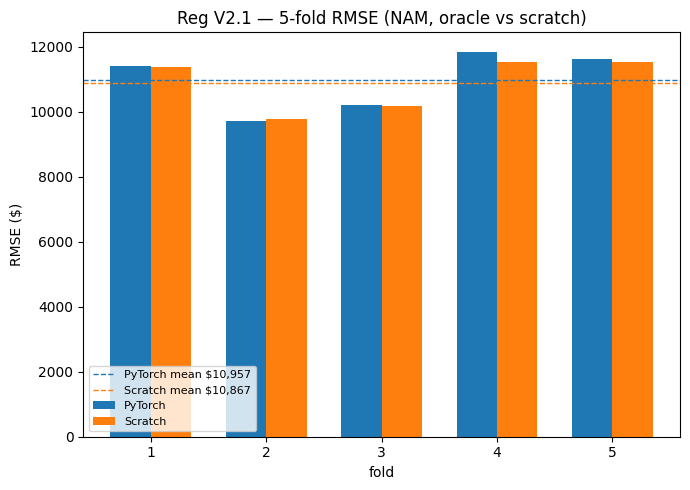

PyTorch RMSE mean+-std: 10957.3 939.2261
Scratch RMSE mean+-std: 10866.9 834.9576


In [11]:
import matplotlib.pyplot as plt

pyt_kf = json.load(open("weights_V2_1/regression_pytorch_kfold_metrics.json"))
scr_kf = json.load(open("weights_V2_1/regression_scratch_kfold_metrics.json"))
pyt_rmse = [r["rmse"] for r in pyt_kf["folds"]]
scr_rmse = [r["rmse"] for r in scr_kf["folds"]]
folds_x = np.arange(1, 6)
width = 0.35
plt.figure(figsize=(7, 5))
plt.bar(folds_x - width / 2, pyt_rmse, width, label="PyTorch")
plt.bar(folds_x + width / 2, scr_rmse, width, label="Scratch")
plt.axhline(pyt_kf["summary"]["rmse"]["mean"], color="C0", linestyle="--", linewidth=1,
            label=f"PyTorch mean ${pyt_kf['summary']['rmse']['mean']:,.0f}")
plt.axhline(scr_kf["summary"]["rmse"]["mean"], color="C1", linestyle="--", linewidth=1,
            label=f"Scratch mean ${scr_kf['summary']['rmse']['mean']:,.0f}")
plt.xticks(folds_x); plt.xlabel("fold"); plt.ylabel("RMSE ($)")
plt.title("Reg V2.1 — 5-fold RMSE (NAM, oracle vs scratch)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("media/kfold_reg_V2_1.png", dpi=150)
plt.show()

print("PyTorch RMSE mean+-std:", pyt_kf["summary"]["rmse"]["mean"], pyt_kf["summary"]["rmse"]["std"])
print("Scratch RMSE mean+-std:", scr_kf["summary"]["rmse"]["mean"], scr_kf["summary"]["rmse"]["std"])